In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [4]:
#time to import all the data yayyyy
s13offm1 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/m1sat.csv',delimiter=',')
s13offm05 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/m05sat.csv',delimiter=',')
s13offm03 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/m03sat.csv',delimiter=',')
s13offm01 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/m01sat.csv',delimiter=',')
s13off0 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/0sat.csv',delimiter=',')
s13off01 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/01sat.csv',delimiter=',')
s13off03 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/03sat.csv',delimiter=',')
s13off05 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/05sat.csv',delimiter=',')
s13off1 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/1sat.csv',delimiter=',')

In [5]:
s24offm1 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/m1sat.csv',delimiter=',')
s24offm05 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/m05sat.csv',delimiter=',')
s24offm03 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/m03sat.csv',delimiter=',')
s24offm01 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/m01sat.csv',delimiter=',')
s24off0 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/0sat.csv',delimiter=',')
s24off01 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/01sat.csv',delimiter=',')
s24off03 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/03sat.csv',delimiter=',')
s24off05 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/05sat.csv',delimiter=',')
s24off1 = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24/1sat.csv',delimiter=',')

In [6]:
speckles13 = [s13offm1, s13offm05, s13offm03, s13offm01, s13off0, s13off01, s13off03, s13off05, s13off1]
speckles24 = [s24offm1, s24offm05, s24offm03, s24offm01, s24off0, s24off01, s24off03, s24off05, s24off1]

In [ ]:
#now to consolidate each dataset into its mean and standard deviation
avgs13 = np.zeros(len(speckles13))
stds13 = np.zeros(len(speckles13))

for i, speckle in enumerate(speckles13):
    avg = np.mean(speckle)
    std = np.std(speckle)
    avgs13[i] = avg
    stds13[i] = std

avgs24 = np.zeros(len(speckles24))
stds24 = np.zeros(len(speckles24))

for i, speckle in enumerate(speckles24):
    avg = np.mean(speckle)
    std = np.std(speckle)
    avgs24[i] = avg
    stds24[i] = std

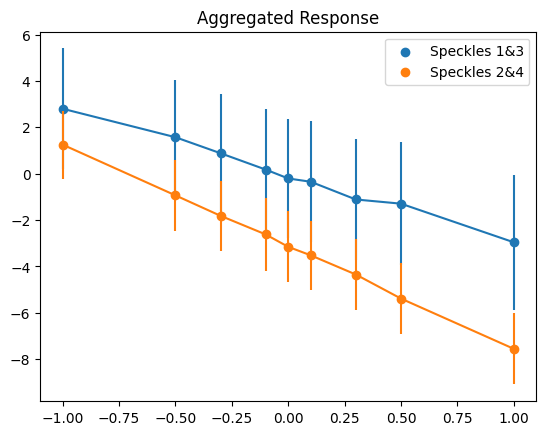

In [12]:
#now to plot (don't forget the error bars)
offsets = np.array([-1, -0.5, -0.3, -0.1, 0, 0.1, 0.3, 0.5, 1])

plt.figure()
plt.scatter(offsets,avgs13,label='Speckles 1&3')
plt.errorbar(offsets,avgs13,stds13)
plt.scatter(offsets,avgs24,label='Speckles 2&4')
plt.errorbar(offsets,avgs24,stds24)
plt.title('Aggregated Response')
plt.legend()
plt.show()

these errorbars are wrong. this is the standard deviation as if you were taking only one measurement and not averaging at all. Technically for these measurements we're averaging over the entire dataset, which makes the standard deviation of that mean equal to zero (because there's only one mean). Maybe I should make this plot with an average over 200 measurements and use those standard deviations instead to get a better idea of the peak performance I can get.

Slope of Speckles 1&3 Response: -2.9059535119616586
Offset of Speckles 1&3 Response: -0.054560233387104806
Slope of Speckles 2&4 Response: -4.40215421699244
Offset of Speckles 2&4 Response: -3.1233040287968503


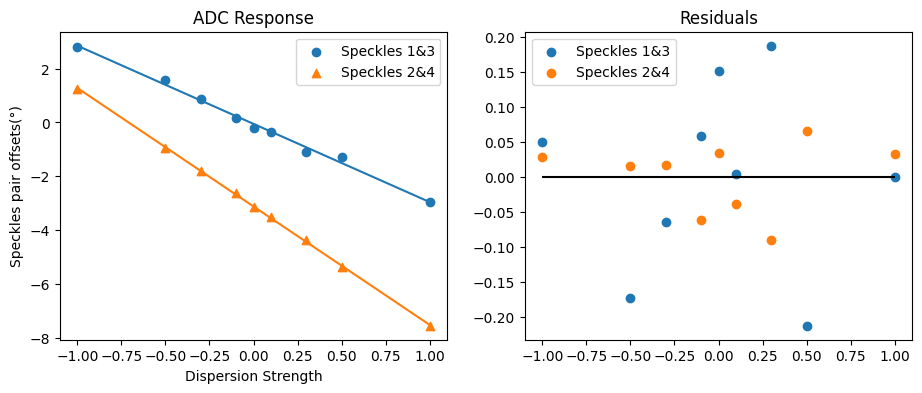

In [22]:
#axing the standard deviations for now and doing a line fit to generate the response and control matrices
b1 = np.zeros(2)
m1 = np.zeros(2)
residuals = np.zeros(shape=(2,len(avgs13)))

avgs = [avgs13, avgs24]

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets,avgs[j],deg=1)
    plt.scatter(offsets, avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets
    residuals[j,:] =  linepoints - avgs[j]
    plt.plot(offsets, linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')


plt.title('ADC Response')
plt.xlabel('Dispersion Strength')
plt.ylabel('Speckles pair offsets(°)')
plt.legend()

plt.subplot(1,2,2)
plt.scatter(offsets,residuals[0,:], label=labels[0])
plt.scatter(offsets,residuals[1,:], label=labels[1])
plt.hlines(0,-1,1,colors='black')
plt.legend()
plt.title('Residuals')
plt.show()

In [27]:
print(avgs13)

[ 2.80141297  1.57237823  0.88178078  0.17731179 -0.20663374 -0.34904047
 -1.11395782 -1.29435649 -2.95993735]


In [39]:
#finding the response/control matrices
response = np.matrix([m1])
ctrl_matrix = np.linalg.pinv(response)
print(ctrl_matrix.T)

ctrl_matrix = ctrl_matrix.T
print(ctrl_matrix[0,1])

[[-0.10444231 -0.15821697]]
-0.15821696968106064


In [30]:
# so does it actually spit out zero at the "zero point"?
zero_angles = np.matrix([-0.20663374,-0.75]).T

result = ctrl_matrix * zero_angles
print(result)

[[0.14024403]]


In [37]:
#I think we need to "train" and "test" again?
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq)
ADC.set_control_mtx(ctrl_matrix)

In [35]:
avgs = np.matrix(avgs)
print(avgs[:,0])
print(avgs)

[[2.80141297]
 [1.25120279]]
[[ 2.80141297  1.57237823  0.88178078  0.17731179 -0.20663374 -0.34904047
  -1.11395782 -1.29435649 -2.95993735]
 [ 1.25120279 -0.93732607 -1.81919369 -2.62155148 -3.15746042 -3.52435588
  -4.35288719 -5.39055234 -7.55761198]]


In [ ]:
avgs = np.matrix(avgs)
commands = np.zeros(len(avgs13))

for i in range(len(avgs13)):
    commands[i] = ADC.calculate_command(avgs[:,i].T)

print(commands)


[ 0.49054756  0.01592193 -0.19573209 -0.39625508 -0.52114512 -0.5940675
 -0.80504495 -0.98806244 -1.50488516]


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_75815/2978227126.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  commands[i] = ADC.calculate_command(avgs[:,i].T)


slope: -1.0000000000000002
offset: -0.4998580956788455


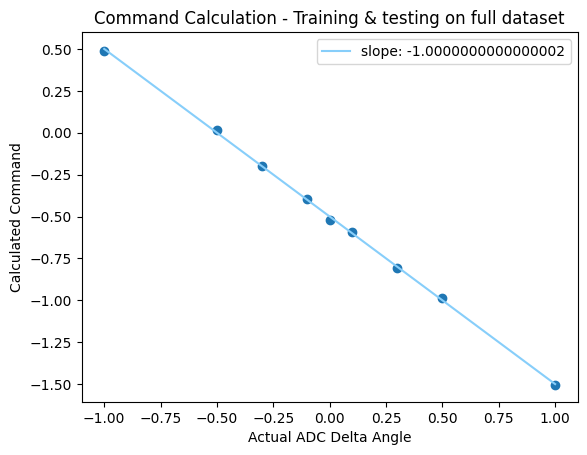

In [42]:
#plotting versus the actual angles:
m, b = np.polyfit(offsets,commands,deg=1)

print(f'slope: {m}')
print(f'offset: {b}')

plt.scatter(offsets,commands)
plt.plot(offsets, m * offsets + b,color='lightskyblue',label=f'slope: {m}')
plt.title('Command Calculation - Training & testing on full dataset')
plt.xlabel('Actual ADC Delta Angle')
plt.ylabel('Calculated Command')
plt.legend()
plt.show()

